In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import pandas as pd
import torch as th
import os
from tqdm import tqdm
from IPython.display import display
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.collections as mc
import numpy as np

from frag_gnn.runner import load_config, init_dataset, init_dataloader
from frag_gnn.pl_model import FragGNNPL
from frag_gnn.utils.misc_utils import to_device
# from frag_gnn.utils.proc_utils import merge_spec_df


In [3]:
os.chdir("/h/adamo/frag-gnn")

In [4]:
# d3_dp = "data/frag/nist20mona23v3_d3_h4_isoFalse_nb3/dags"
# d4_dp = "data/frag/nist20mona23v3_d4_h4_isoFalse_nb3/dags"
split_dp = "data/split/nist20mona23v3_d4_wr00_inchikey"
# scaffold_dp = "data/split/nist20mona23v3_d4_wr00_scaffold"
proc_dp = "data/proc/nist20mona23v3"
template_config_fp = "config/template.yml"
d3_config_fp = "config/frag_stats/d3.yml"
d4_config_fp = "config/frag_stats/d4.yml"
d3_results_fp = "figs/frag_stats/d3.csv"
d4_results_fp = "figs/frag_stats/d4.csv"

In [5]:
# train_ids = pd.read_csv(os.path.join(split_dp,"train_ids.csv"))
# val_ids = pd.read_csv(os.path.join(split_dp,"val_ids.csv"))
# test_ids = pd.read_csv(os.path.join(split_dp,"test_ids.csv"))
# all_ids = pd.concat([train_ids,val_ids,test_ids],axis=0)
# display(all_ids)

In [6]:
# spec_df = os.path.join(proc_dp,"spec_df.pkl")
# mol_df = os.path.join(proc_dp,"mol_df.pkl")
# m_spec_df = merge_spec_df(spec_df[spec_df["spec_id"].isin(all_ids["spec_id"])],keep_ces=False)

In [7]:
# all_ids.to_csv(os.path.join(split_dp,"all_ids.csv"),index=False)

In [8]:
col_d = {
    "index":"Statistic",
    "min":"Min",
    "25%": "25\%",
    "50%": "50\%",
    "75%": "75\%",
    "max":"Max"
}
stats_d = {
    "pred_formula_count": r"\# Formulae $f$",
    "pred_node_count": r"\# Nodes $n$",
    "pred_nb_node_count": r"\# Nodes $\tilde{n}$",
    "pred_edge_count": r"\# Edges $e$",
    "recall": "Recall",
    "wrecall": "Weighted Recall",
    "precision": "Precision",
    "wprecision": "Weighted Precision",
}
fmt_d = {
    "pred_formula_count": lambda x: f"{int(x)}",
    "pred_node_count": lambda x: f"{int(x)}",
    "pred_nb_node_count": lambda x: f"{int(x)}",
    "pred_edge_count": lambda x: f"{int(x)}",
    "recall": lambda x: f"{x:.2f}",
    "wrecall": lambda x: f"{x:.2f}",
    "precision": lambda x: f"{x:.2f}",
    "wprecision": lambda x: f"{x:.2f}",
}

In [9]:
list(stats_d.values())

['\\# Formulae $f$',
 '\\# Nodes $n$',
 '\\# Nodes $\\tilde{n}$',
 '\\# Edges $e$',
 'Recall',
 'Weighted Recall',
 'Precision',
 'Weighted Precision']

In [10]:
d3_results_df = pd.read_csv(d3_results_fp)
d3_summary_df = d3_results_df[list(stats_d.keys())].describe().T
d3_summary_df = d3_summary_df.drop(columns=["count","mean","std"])
d3_summary_df = d3_summary_df.reset_index()
d3_summary_df = d3_summary_df.apply(
    lambda row: row.apply(lambda x: fmt_d[row["index"]](x) if isinstance(x, (int,float)) else x),
    axis=1
)
d3_summary_df = d3_summary_df.rename(columns=col_d)
d3_summary_df.loc[:,"Statistic"] = d3_summary_df["Statistic"].map(stats_d)
display(d3_summary_df)

,Statistic,Min,25\%,50\%,75\%,Max
0,\# Formulae $f$,4,323,527,838,7239
1,\# Nodes $n$,10,167,280,474,5022
2,\# Nodes $\tilde{n}$,9,104,173,308,4518
3,\# Edges $e$,20,662,1156,2138,44952
4,Recall,0.00,0.51,0.64,0.77,1.00
5,Weighted Recall,0.00,0.75,0.88,0.96,1.00
6,Precision,0.00,0.05,0.08,0.13,0.53
7,Weighted Precision,0.00,0.04,0.07,0.12,0.60


In [11]:
d3_latex_df = d3_summary_df.to_latex(index=False,escape=False,column_format="lccccc")
print(d3_latex_df)

\begin{tabular}{lccccc}
\toprule
Statistic & Min & 25\% & 50\% & 75\% & Max \\
\midrule
\# Formulae $f$ & 4 & 323 & 527 & 838 & 7239 \\
\# Nodes $n$ & 10 & 167 & 280 & 474 & 5022 \\
\# Nodes $\tilde{n}$ & 9 & 104 & 173 & 308 & 4518 \\
\# Edges $e$ & 20 & 662 & 1156 & 2138 & 44952 \\
Recall & 0.00 & 0.51 & 0.64 & 0.77 & 1.00 \\
Weighted Recall & 0.00 & 0.75 & 0.88 & 0.96 & 1.00 \\
Precision & 0.00 & 0.05 & 0.08 & 0.13 & 0.53 \\
Weighted Precision & 0.00 & 0.04 & 0.07 & 0.12 & 0.60 \\
\bottomrule
\end{tabular}



In [12]:
d4_results_df = pd.read_csv(d4_results_fp)
d4_summary_df = d4_results_df[list(stats_d.keys())].describe().T
d4_summary_df = d4_summary_df.drop(columns=["count","mean","std"])
d4_summary_df = d4_summary_df.reset_index()
d4_summary_df = d4_summary_df.apply(
    lambda row: row.apply(lambda x: fmt_d[row["index"]](x) if isinstance(x, (int,float)) else x),
    axis=1
)
d4_summary_df = d4_summary_df.rename(columns=col_d)
d4_summary_df.loc[:,"Statistic"] = d4_summary_df["Statistic"].map(stats_d)
display(d4_summary_df)

,Statistic,Min,25\%,50\%,75\%,Max
0,\# Formulae $f$,4,388,679,1160,13146
1,\# Nodes $n$,10,333,677,1392,32902
2,\# Nodes $\tilde{n}$,9,183,379,865,31688
3,\# Edges $e$,20,2288,4790,10020,249138
4,Recall,0.00,0.63,0.75,0.85,1.00
5,Weighted Recall,0.00,0.86,0.94,0.98,1.00
6,Precision,0.00,0.04,0.08,0.13,0.52
7,Weighted Precision,0.00,0.03,0.07,0.13,0.67


In [13]:
d4_latex_df = d4_summary_df.to_latex(index=False,escape=False,column_format="lccccc")
print(d4_latex_df)

\begin{tabular}{lccccc}
\toprule
Statistic & Min & 25\% & 50\% & 75\% & Max \\
\midrule
\# Formulae $f$ & 4 & 388 & 679 & 1160 & 13146 \\
\# Nodes $n$ & 10 & 333 & 677 & 1392 & 32902 \\
\# Nodes $\tilde{n}$ & 9 & 183 & 379 & 865 & 31688 \\
\# Edges $e$ & 20 & 2288 & 4790 & 10020 & 249138 \\
Recall & 0.00 & 0.63 & 0.75 & 0.85 & 1.00 \\
Weighted Recall & 0.00 & 0.86 & 0.94 & 0.98 & 1.00 \\
Precision & 0.00 & 0.04 & 0.08 & 0.13 & 0.52 \\
Weighted Precision & 0.00 & 0.03 & 0.07 & 0.13 & 0.67 \\
\bottomrule
\end{tabular}



In [14]:
d3_summary_idx_df = d3_summary_df.set_index("Statistic")
d4_summary_idx_df = d4_summary_df.set_index("Statistic")
both_summary_df = pd.concat([d3_summary_idx_df,d4_summary_idx_df],axis=1, keys=["D3","D4"])
both_summary_df = both_summary_df.reset_index()
new_columns = pd.MultiIndex.from_tuples(
    [('', 'Statistics')] + [(key, col) for key, col in both_summary_df.columns[1:]]
)
both_summary_df.columns = new_columns
display(both_summary_df)

D3                             D4              \
             Statistics   Min  25\%  50\%  75\%    Max   Min  25\%  50\%   
0       \# Formulae $f$     4   323   527   838   7239     4   388   679   
1          \# Nodes $n$    10   167   280   474   5022    10   333   677   
2  \# Nodes $\tilde{n}$     9   104   173   308   4518     9   183   379   
3          \# Edges $e$    20   662  1156  2138  44952    20  2288  4790   
4                Recall  0.00  0.51  0.64  0.77   1.00  0.00  0.63  0.75   
5       Weighted Recall  0.00  0.75  0.88  0.96   1.00  0.00  0.86  0.94   
6             Precision  0.00  0.05  0.08  0.13   0.53  0.00  0.04  0.08   
7    Weighted Precision  0.00  0.04  0.07  0.12   0.60  0.00  0.03  0.07   

                  
    75\%     Max  
0   1160   13146  
1   1392   32902  
2    865   31688  
3  10020  249138  
4   0.85    1.00  
5   0.98    1.00  
6   0.13    0.52  
7   0.13    0.67

In [ ]:
both_latex_df = both_summary_df.to_latex(index=False,escape=False)
print(both_latex_df)
# note: this needs to be reformatted a bit in the paper

\begin{tabular}{lllllllllll}
\toprule
 & \multicolumn{5}{r}{D3} & \multicolumn{5}{r}{D4} \\
Statistics & Min & 25\% & 50\% & 75\% & Max & Min & 25\% & 50\% & 75\% & Max \\
\midrule
\# Formulae $f$ & 4 & 323 & 527 & 838 & 7239 & 4 & 388 & 679 & 1160 & 13146 \\
\# Nodes $n$ & 10 & 167 & 280 & 474 & 5022 & 10 & 333 & 677 & 1392 & 32902 \\
\# Nodes $\tilde{n}$ & 9 & 104 & 173 & 308 & 4518 & 9 & 183 & 379 & 865 & 31688 \\
\# Edges $e$ & 20 & 662 & 1156 & 2138 & 44952 & 20 & 2288 & 4790 & 10020 & 249138 \\
Recall & 0.00 & 0.51 & 0.64 & 0.77 & 1.00 & 0.00 & 0.63 & 0.75 & 0.85 & 1.00 \\
Weighted Recall & 0.00 & 0.75 & 0.88 & 0.96 & 1.00 & 0.00 & 0.86 & 0.94 & 0.98 & 1.00 \\
Precision & 0.00 & 0.05 & 0.08 & 0.13 & 0.53 & 0.00 & 0.04 & 0.08 & 0.13 & 0.52 \\
Weighted Precision & 0.00 & 0.04 & 0.07 & 0.12 & 0.60 & 0.00 & 0.03 & 0.07 & 0.13 & 0.67 \\
\bottomrule
\end{tabular}



In [13]:
def plot_histogram(values, title, log=False, bins=50, max_value=None):
    
    fig, ax = plt.subplots()

    # Define colors and opacity
    hist_color = 'skyblue'
    hist_alpha = 0.7

    # Create bins with optional maximum value
    if max_value is not None:
        min_value = np.min(values)
        bin_edges = np.linspace(min_value, max_value, bins + 1)
        ax.hist(values, bins=bin_edges, color=hist_color, alpha=hist_alpha, edgecolor='black')
    else:
        ax.hist(values, bins=bins, color=hist_color, alpha=hist_alpha, edgecolor='black')

    # Calculate mean and median
    mean_value = np.mean(values)
    median_value = np.median(values)

    # Plot vertical lines for mean and median with enhanced colors
    ax.axvline(mean_value, color="darkorange", linestyle="dashed", linewidth=2,
               label=f"Mean: {mean_value:.2f}")
    ax.axvline(median_value, color="forestgreen", linestyle="dotted", linewidth=2,
               label=f"Median: {median_value:.2f}")

    ax.set_title(title, fontsize=14)
    ax.set_yscale("log" if log else "linear")
    ax.legend()

    plt.show()

In [14]:
def plot_histogram_with_boxplot(values, title, log=False, bins=50, max_value=None):
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Define histogram colors and opacity
    hist_color = 'skyblue'
    hist_alpha = 0.7
    
    # Create bins with optional maximum value
    if max_value is not None:
        min_value = np.min(values)
        bin_edges = np.linspace(min_value, max_value, bins + 1)
        ax.hist(values, bins=bin_edges, color=hist_color, alpha=hist_alpha, edgecolor='black')
    else:
        ax.hist(values, bins=bins, color=hist_color, alpha=hist_alpha, edgecolor='black')
    
    ax.set_title(title, fontsize=14)
    ax.set_yscale("log" if log else "linear")
    
    # Create an inset axis for the boxplot in the vertical middle of the plot.
    # The coordinates [left, bottom, width, height] are in figure fraction.
    # Here, bottom is set to 0.45 to place the boxplot roughly in the middle.
    box_ax = fig.add_axes([0.15, 0.45, 0.7, 0.1])
    box_ax.boxplot(values, vert=False, patch_artist=True,
                   boxprops=dict(facecolor='lightgrey', color='black'),
                   medianprops=dict(color='red', linewidth=2))
    
    # Remove ticks and spines from the inset boxplot to reduce visual clutter
    box_ax.set_yticks([])
    box_ax.set_xticks([])
    for spine in box_ax.spines.values():
        spine.set_visible(False)
    
    plt.show()

In [15]:
# plot_histogram(results["wrecall"].numpy(), "Weighted Recall")

In [16]:
# plot_histogram(results["wprecision"].numpy(), "Weighted Precision")

In [17]:
# plot_histogram(results["pred_formula_count"].numpy(), "Formula Count", max_value=4000)

In [18]:
# plot_histogram(results["pred_node_count"].numpy(), "Node Count", max_value=2000)

In [ ]:
# plot_histogram(results["pred_nb_node_count"].numpy(), "NB Node Count", max_value=2000)

NameError: name 'results' is not defined

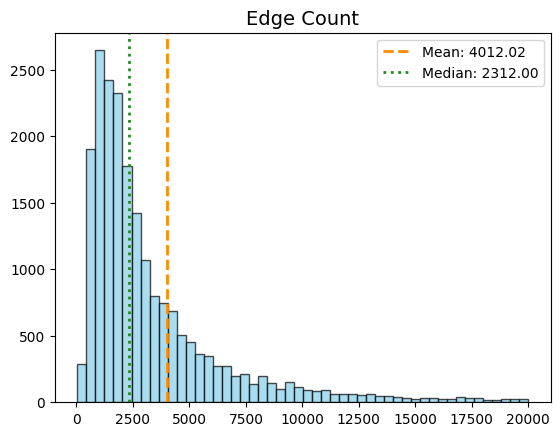

In [ ]:
# plot_histogram(results["pred_edge_count"].numpy(), "Edge Count", max_value=20000)